<a href="https://colab.research.google.com/github/OlegSamarsky/MN/blob/main/%D0%9B%D0%A0_11_%D0%A1%D0%B0%D0%BC%D0%B0%D1%80%D1%81%D1%8C%D0%BA%D0%B8%D0%B9_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Підключення бібліотек та завантаження датасету з Kaggle

In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix

SEED = 101
keras.utils.set_random_seed(SEED)

kaggle_dir = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print("Каталог датасету:", kaggle_dir)

df_train = pd.read_csv(os.path.join(kaggle_dir, "Train.csv"))
df_test = pd.read_csv(os.path.join(kaggle_dir, "Test.csv"))

print(f"Тренувальних зразків: {len(df_train)}")
print(f"Тестових зразків:     {len(df_test)}")
print(f"Кількість класів:     {df_train['ClassId'].nunique()}")
df_train.head()

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Каталог датасету: /kaggle/input/gtsrb-german-traffic-sign
Тренувальних зразків: 39209
Тестових зразків:     12630
Кількість класів:     43


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


2. Огляд даних та візуалізація зображень дорожніх знаків

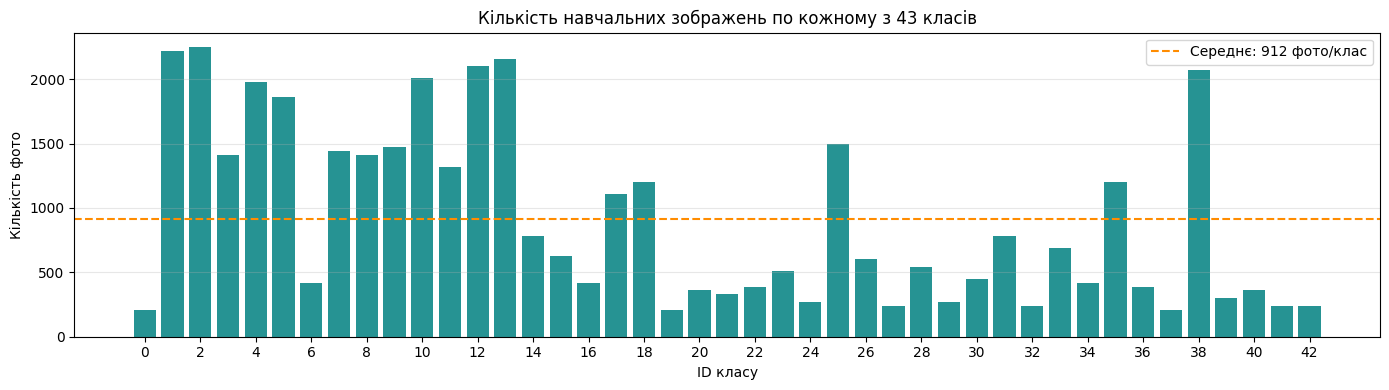

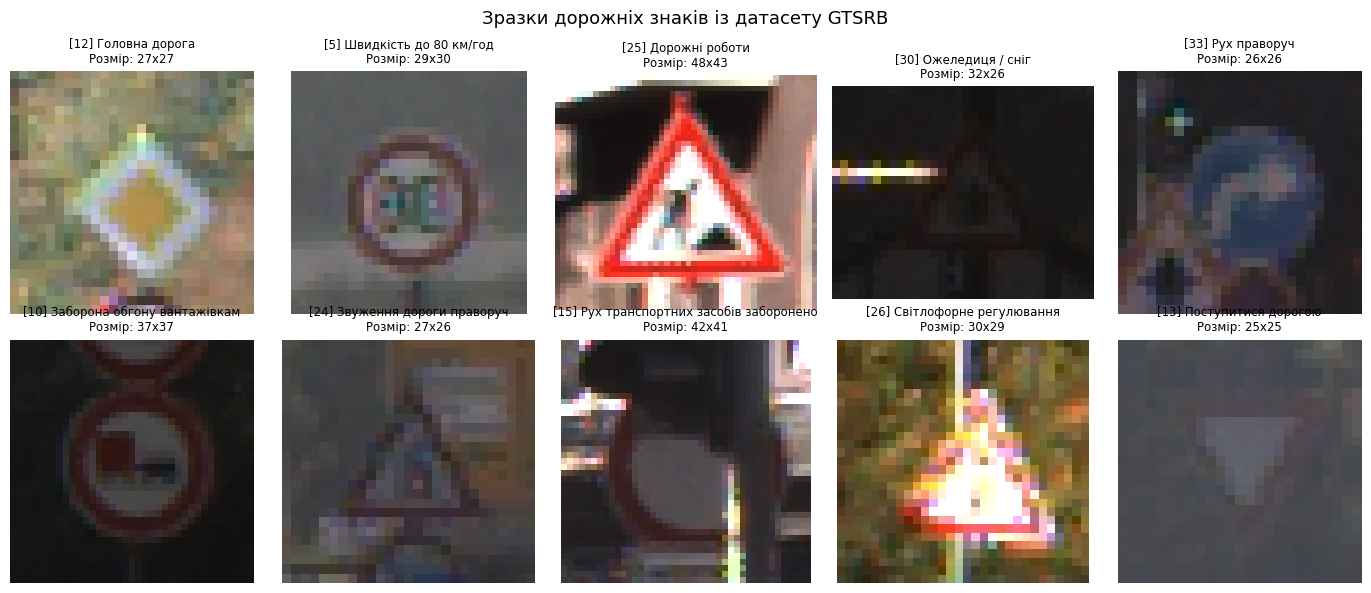

In [3]:
SIGN_LABELS = {
    0: "Швидкість до 20 км/год", 1: "Швидкість до 30 км/год", 2: "Швидкість до 50 км/год",
    3: "Швидкість до 60 км/год", 4: "Швидкість до 70 км/год", 5: "Швидкість до 80 км/год",
    6: "Кінець зони 80 км/год", 7: "Швидкість до 100 км/год", 8: "Швидкість до 120 км/год",
    9: "Заборона обгону", 10: "Заборона обгону вантажівкам", 11: "Перехрестя з другорядною",
    12: "Головна дорога", 13: "Поступитися дорогою", 14: "Проїзд без зупинки заборонено",
    15: "Рух транспортних засобів заборонено", 16: "Рух вантажівок заборонено", 17: "В'їзд заборонено",
    18: "Інша небезпека", 19: "Небезпечний поворот ліворуч", 20: "Небезпечний поворот праворуч",
    21: "Декілька небезпечних поворотів", 22: "Нерівна дорога", 23: "Слизька дорога",
    24: "Звуження дороги праворуч", 25: "Дорожні роботи", 26: "Світлофорне регулювання",
    27: "Пішохідний перехід", 28: "Діти", 29: "Виїзд велосипедистів",
    30: "Ожеледиця / сніг", 31: "Дикі тварини", 32: "Кінець усіх заборон і обмежень",
    33: "Рух праворуч", 34: "Рух ліворуч", 35: "Рух прямо",
    36: "Рух прямо або праворуч", 37: "Рух прямо або ліворуч", 38: "Об'їзд перешкоди з правого боку",
    39: "Об'їзд перешкоди з лівого боку", 40: "Круговий рух", 41: "Кінець заборони обгону",
    42: "Кінець заборони обгону вантажівкам"
}

# 1. Гістограма наповненості класів у навчальному наборі
counts_by_class = df_train["ClassId"].value_counts().sort_index()

plt.figure(figsize=(14, 4))
plt.bar(counts_by_class.index, counts_by_class.values, color="teal", alpha=0.85)
plt.axhline(counts_by_class.mean(), color="darkorange", linestyle="--", label=f"Середнє: {counts_by_class.mean():.0f} фото/клас")
plt.title("Кількість навчальних зображень по кожному з 43 класів")
plt.xlabel("ID класу")
plt.ylabel("Кількість фото")
plt.xticks(range(0, 43, 2))
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Виведення 10 зображень із різних класів набору GTSRB
chosen_classes = np.random.default_rng(SEED).choice(43, size=10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for ax, cls_id in zip(axes.flat, chosen_classes):
    row = df_train[df_train["ClassId"] == cls_id].iloc[0]
    img = Image.open(os.path.join(kaggle_dir, row["Path"]))
    ax.imshow(img)
    ax.set_title(f"[{cls_id}] {SIGN_LABELS[cls_id]}\nРозмір: {img.size[0]}x{img.size[1]}", fontsize=8.5)
    ax.axis("off")

plt.suptitle("Зразки дорожніх знаків із датасету GTSRB", fontsize=13)
plt.tight_layout()
plt.show()

3. Масштабування зображень та поділ на вибірки

In [4]:
TARGET_SIZE = 40
TOTAL_CLASSES = 43

def prepare_dataset(meta_df, base_dir, size=TARGET_SIZE):
    n = len(meta_df)
    X_arr = np.zeros((n, size, size, 3), dtype=np.float32)
    y_arr = meta_df["ClassId"].to_numpy(dtype=np.int64)

    for i, rel_path in enumerate(meta_df["Path"]):
        with Image.open(os.path.join(base_dir, rel_path)) as im:
            im_rgb = im.convert("RGB").resize((size, size), Image.Resampling.BICUBIC)
            X_arr[i] = np.asarray(im_rgb, dtype=np.float32) / 255.0
    return X_arr, y_arr

print(f"Підготовка зображень у форматі {TARGET_SIZE}x{TARGET_SIZE}...")
X_all, y_all = prepare_dataset(df_train, kaggle_dir, TARGET_SIZE)
X_test_imgs, y_test_lbls = prepare_dataset(df_test, kaggle_dir, TARGET_SIZE)

# Відокремлюємо 85% на навчання та 15% на валідацію зі збереженням балансу класів
X_train_imgs, X_val_imgs, y_train_lbls, y_val_lbls = train_test_split(
    X_all, y_all, test_size=0.15, random_state=SEED, stratify=y_all
)

print(f"X_train_imgs: {X_train_imgs.shape} | y_train_lbls: {y_train_lbls.shape}")
print(f"X_val_imgs:   {X_val_imgs.shape} | y_val_lbls:   {y_val_lbls.shape}")
print(f"X_test_imgs:  {X_test_imgs.shape} | y_test_lbls:  {y_test_lbls.shape}")

Підготовка зображень у форматі 40x40...
X_train_imgs: (33327, 40, 40, 3) | y_train_lbls: (33327,)
X_val_imgs:   (5882, 40, 40, 3) | y_val_lbls:   (5882,)
X_test_imgs:  (12630, 40, 40, 3) | y_test_lbls:  (12630,)


4. Підбір архітектури згорткової нейронної мережі

Порівняємо дві різні за структурою згорткові мережі:

ConvNet_Base — класична тризгорткова модель (32 -> 64 -> 128 фільтрів) із переходом у повнозв'язний шар через Flatten().

ConvNet_GAP_BN — модель із подвійними згортковими блоками, нормалізацією BatchNormalization, просторовою регуляризацією SpatialDropout2D та шаром GlobalAveragePooling2D() замість громіздкого Flatten().

In [5]:
def create_convnet_base(shape=(TARGET_SIZE, TARGET_SIZE, 3), n_classes=TOTAL_CLASSES):
    return keras.Sequential([
        keras.Input(shape=shape),
        layers.Conv2D(32, kernel_size=3, activation="relu"),
        layers.MaxPooling2D(pool_size=2),

        layers.Conv2D(64, kernel_size=3, activation="relu"),
        layers.MaxPooling2D(pool_size=2),

        layers.Conv2D(128, kernel_size=3, activation="relu"),
        layers.MaxPooling2D(pool_size=2),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.30),
        layers.Dense(n_classes, activation="softmax")
    ], name="ConvNet_Base")


def create_convnet_gap_bn(shape=(TARGET_SIZE, TARGET_SIZE, 3), n_classes=TOTAL_CLASSES):
    return keras.Sequential([
        keras.Input(shape=shape),

        # Згортковий блок 1
        layers.Conv2D(32, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(32, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.SpatialDropout2D(0.15),

        # Згортковий блок 2
        layers.Conv2D(64, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(64, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.SpatialDropout2D(0.20),

        # Згортковий блок 3 та глобальне усереднення карт ознак
        layers.Conv2D(128, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.GlobalAveragePooling2D(),

        # Класифікаційна голова
        layers.Dense(128, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(0.35),
        layers.Dense(n_classes, activation="softmax")
    ], name="ConvNet_GAP_BN")


architectures = {
    "ConvNet_Base": create_convnet_base(),
    "ConvNet_GAP_BN": create_convnet_gap_bn()
}

train_logs = {}
summary_rows = []

for arch_name, net in architectures.items():
    print(f"\n--- Тренування {arch_name} (параметрів: {net.count_params():,}) ---")
    net.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )
    callbacks_list = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
    ]

    hist = net.fit(
        X_train_imgs, y_train_lbls,
        validation_data=(X_val_imgs, y_val_lbls),
        epochs=15,
        batch_size=64,
        callbacks=callbacks_list,
        verbose=1
    )
    train_logs[arch_name] = hist
    v_loss, v_acc = net.evaluate(X_val_imgs, y_val_lbls, verbose=0)
    summary_rows.append({
        "Модель": arch_name,
        "Кількість параметрів": net.count_params(),
        "Епох": len(hist.history["loss"]),
        "Val Loss": round(v_loss, 4),
        "Val Accuracy (%)": round(v_acc * 100, 2)
    })

comparison_table = pd.DataFrame(summary_rows).sort_values(by="Val Accuracy (%)", ascending=False).reset_index(drop=True)
print("\nПорівняльна таблиця архітектур:")
display(comparison_table)

best_name = comparison_table.loc[0, "Модель"]
selected_model = architectures[best_name]
selected_history = train_logs[best_name]

print(f"\nНайкраща обрана модель: {best_name}")
selected_model.summary()


--- Тренування ConvNet_Base (параметрів: 246,379) ---
Epoch 1/15
521/521 ━━━━━━━━━━━━━━━━━━━━ 24s 28ms/step - accuracy: 0.5699 - loss: 1.5312 - val_accuracy: 0.9124 - val_loss: 0.3022 - learning_rate: 0.0010
Epoch 2/15
521/521 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9174 - loss: 0.2789 - val_accuracy: 0.9777 - val_loss: 0.0984 - learning_rate: 0.0010
Epoch 3/15
521/521 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9603 - loss: 0.1367 - val_accuracy: 0.9852 - val_loss: 0.0555 - learning_rate: 0.0010
Epoch 4/15
521/521 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9740 - loss: 0.0896 - val_accuracy: 0.9849 - val_loss: 0.0515 - learning_rate: 0.0010
Epoch 5/15
521/521 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9802 - loss: 0.0653 - val_accuracy: 0.9929 - val_loss: 0.0305 - learning_rate: 0.0010
Epoch 6/15
521/521 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9849 - loss: 0.0517 - val_accuracy: 0.9906 - val_loss: 0.0342 - learning_rate: 0.0010
Epoch 7/15
521/521 ━━━━━━━━━━━━

,Модель,Кількість параметрів,Епох,Val Loss,Val Accuracy (%)
0,ConvNet_GAP_BN,162827,15,0.0033,99.90
1,ConvNet_Base,246379,15,0.0133,99.76



Найкраща обрана модель: ConvNet_GAP_BN


Model: "ConvNet_GAP_BN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 40, 40, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 40, 40, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 40, 40, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 40, 40, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 20, 20, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d               │ (None, 20, 20, 32)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 20, 20, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 20, 20, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 20, 20, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 20, 20, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_1             │ (None, 10, 10, 64)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 10, 10, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 10, 10, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,38

 Total params: 486,691 (1.86 MB)

 Trainable params: 161,931 (632.54 KB)

 Non-trainable params: 896 (3.50 KB)

 Optimizer params: 323,864 (1.24 MB)

5. Графіки кривих навчання

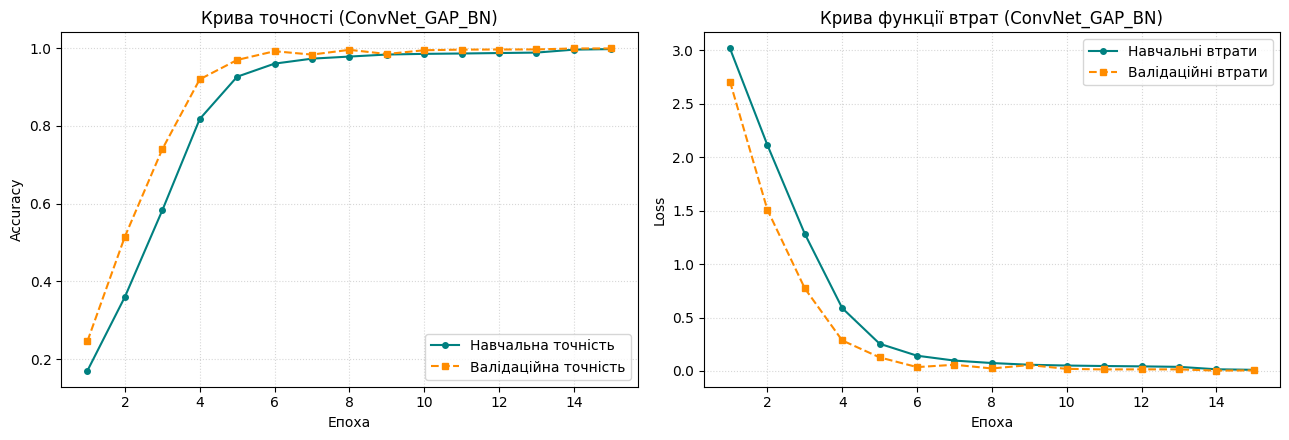

In [7]:
ep_range = np.arange(1, len(selected_history.history["loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Графік точності (Accuracy)
ax1.plot(ep_range, selected_history.history["accuracy"], color="teal", marker="o", ms=4, label="Навчальна точність")
ax1.plot(ep_range, selected_history.history["val_accuracy"], color="darkorange", linestyle="--", marker="s", ms=4, label="Валідаційна точність")
ax1.set_title(f"Крива точності ({best_name})")
ax1.set_xlabel("Епоха")
ax1.set_ylabel("Accuracy")
ax1.legend()
ax1.grid(True, linestyle=":", alpha=0.5)

# Графік втрат (Loss)
ax2.plot(ep_range, selected_history.history["loss"], color="teal", marker="o", ms=4, label="Навчальні втрати")
ax2.plot(ep_range, selected_history.history["val_loss"], color="darkorange", linestyle="--", marker="s", ms=4, label="Валідаційні втрати")
ax2.set_title(f"Крива функції втрат ({best_name})")
ax2.set_xlabel("Епоха")
ax2.set_ylabel("Loss")
ax2.legend()
ax2.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

6. Перевірка на тестовій вибірці та візуалізація класифікації

Тестова точність (Test Accuracy): 98.33% (12419 із 12630)
Тестові втрати (Test Loss):       0.0642
Середній F1-score (Macro):        0.9710

Найчастіші помилки розпізнавання:
  Справжній: [21] Декілька небезпечних поворотів -> Прогноз: [12] Головна дорога (30 випадків)
  Справжній: [22] Нерівна дорога -> Прогноз: [25] Дорожні роботи (19 випадків)
  Справжній: [8] Швидкість до 120 км/год -> Прогноз: [5] Швидкість до 80 км/год (12 випадків)
  Справжній: [6] Кінець зони 80 км/год -> Прогноз: [32] Кінець усіх заборон і обмежень (9 випадків)
  Справжній: [12] Головна дорога -> Прогноз: [32] Кінець усіх заборон і обмежень (9 випадків)


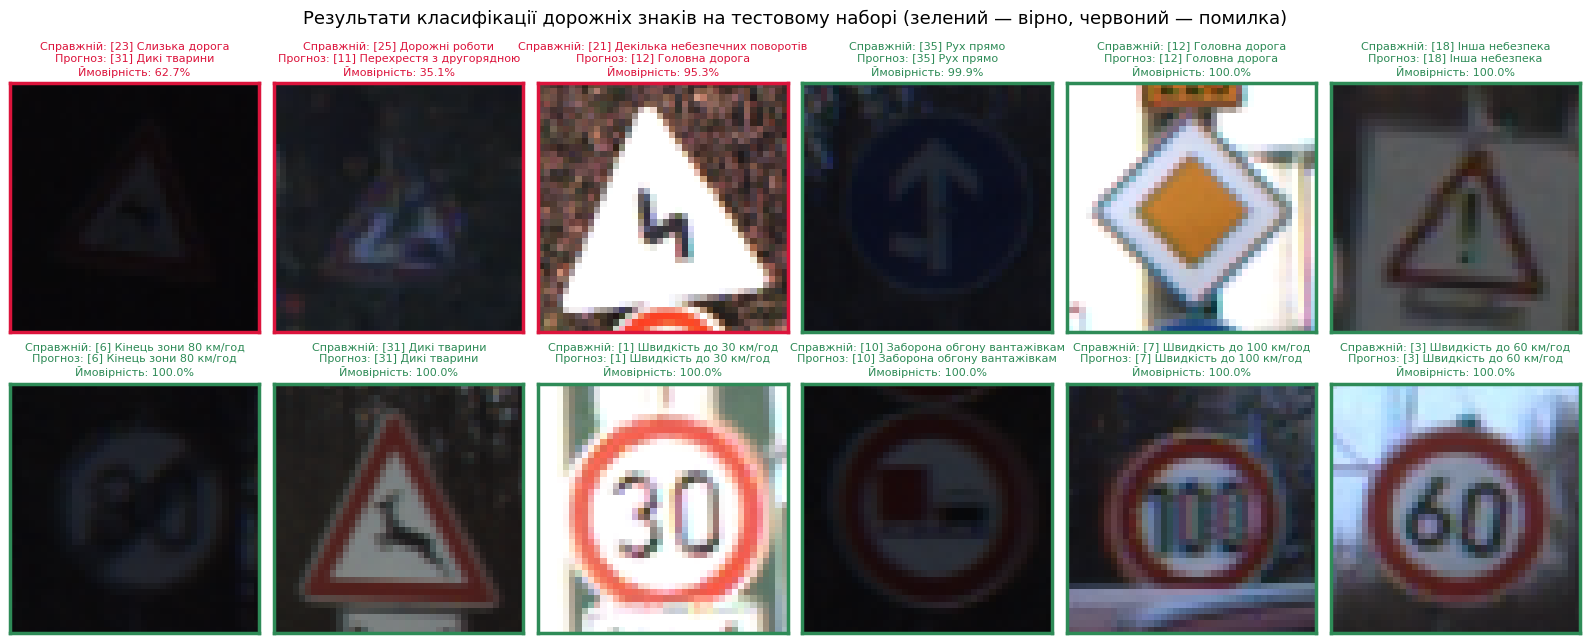

In [8]:
final_test_loss, final_test_acc = selected_model.evaluate(X_test_imgs, y_test_lbls, verbose=0)
pred_probs = selected_model.predict(X_test_imgs, verbose=0)
pred_classes = np.argmax(pred_probs, axis=1)
pred_conf = pred_probs.max(axis=1)
macro_f1 = f1_score(y_test_lbls, pred_classes, average="macro")

print(f"Тестова точність (Test Accuracy): {final_test_acc:.2%} ({(pred_classes == y_test_lbls).sum()} із {len(y_test_lbls)})")
print(f"Тестові втрати (Test Loss):       {final_test_loss:.4f}")
print(f"Середній F1-score (Macro):        {macro_f1:.4f}")

# Топ-5 найчастіших плутанин між класами
err_matrix = confusion_matrix(y_test_lbls, pred_classes)
np.fill_diagonal(err_matrix, 0)
most_confused = np.dstack(np.unravel_index(np.argsort(err_matrix.ravel())[::-1], err_matrix.shape))[0][:5]

print("\nНайчастіші помилки розпізнавання:")
for t_cls, p_cls in most_confused:
    if err_matrix[t_cls, p_cls] > 0:
        print(f"  Справжній: [{t_cls}] {SIGN_LABELS[t_cls]} -> Прогноз: [{p_cls}] {SIGN_LABELS[p_cls]} ({err_matrix[t_cls, p_cls]} випадків)")

# Візуалізація 12 прогнозів (3 помилкових приклади + 9 правильних)
rng = np.random.default_rng(SEED)
mistakes = np.flatnonzero(pred_classes != y_test_lbls)
corrects = np.flatnonzero(pred_classes == y_test_lbls)

chosen_mistakes = rng.choice(mistakes, size=min(3, len(mistakes)), replace=False) if len(mistakes) > 0 else []
chosen_corrects = rng.choice(corrects, size=12 - len(chosen_mistakes), replace=False)
display_idx = np.concatenate([chosen_mistakes, chosen_corrects]).astype(int)

fig, axes = plt.subplots(2, 6, figsize=(16, 6.8))
for ax, idx in zip(axes.flat, display_idx):
    ok = (pred_classes[idx] == y_test_lbls[idx])
    frame_col = "seagreen" if ok else "crimson"

    ax.imshow(X_test_imgs[idx])
    ax.set_title(
        f"Справжній: [{y_test_lbls[idx]}] {SIGN_LABELS[y_test_lbls[idx]]}\n"
        f"Прогноз: [{pred_classes[idx]}] {SIGN_LABELS[pred_classes[idx]]}\n"
        f"Ймовірність: {pred_conf[idx]:.1%}",
        color=frame_col,
        fontsize=8
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for border in ax.spines.values():
        border.set_visible(True)
        border.set_edgecolor(frame_col)
        border.set_linewidth(2.5)

plt.suptitle("Результати класифікації дорожніх знаків на тестовому наборі (зелений — вірно, червоний — помилка)", fontsize=13)
plt.tight_layout()
plt.show()

##7. Висновки

У цій роботі я використав набір даних GTSRB із Kaggle на 43 класи дорожніх знаків, привів усі зображення до формату $40 \times 40$ пікселів і поділив їх на навчальну (33 327 фото), валідаційну (5 882) та тестову (12 630) вибірки. Порівняння двох згорткових мереж показало, що архітектура `ConvNet_GAP_BN` із нормалізацією пакетів та глобальним усередненням виявилася кращою за базову `ConvNet_Base`: на валідації вона досягла 99,90% точності проти 99,76%, маючи при цьому менше параметрів (162 827 проти 246 379). На кривих навчання видно, що модель стабільно виходить на плато приблизно до 6–7 епохи, а навчальна й валідаційна криві йдуть майже поруч, тож перенавчання немає. На тестовому наборі фінальна мережа правильно визначила 12 419 знаків із 12 630, отримавши точність 98,33%, тестові втрати 0,0642 та середній F1-score 0,9710. Як показує візуалізація прогнозів, чіткі знаки розпізнаються з упевненістю 99,9–100%, а неточності трапляються переважно на темних або розмитих кадрах і між схожими за виглядом знаками (наприклад, «Декілька небезпечних поворотів» інколи плутається з «Головною дорогою», а «Нерівна дорога» — з «Дорожніми роботами»).